# KBOC Drift-Aware Authentication POC

This notebook implements a keystroke-only proof of concept using the KBOC Development set. It compares a fixed user profile with an adaptive profile that can follow gradual behavioral change.

**Dataset limitation:** KBOC contains key press/release events and timing. It does not contain scrolling, touch pressure, swipe direction, gait, or accelerometer data. Those modalities require a future data-collection phase.

## Evaluation protocol

- Users: 10
- Samples per user: 24
- Enrollment: samples 1-4
- Genuine evaluation: samples 5-14
- Impostor evaluation: samples 15-24
- The supplied development labels are used only for evaluation and controlled adaptation experiments.

The drift experiment is simulated because the dataset is not a six-month longitudinal collection.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook is expected to be in the project root.
PROJECT_DIR = Path.cwd()
DB_DIR = PROJECT_DIR / 'Development_db'
if not DB_DIR.exists():
    DB_DIR = PROJECT_DIR.parent / 'Development_db'
if not DB_DIR.exists():
    raise FileNotFoundError('Development_db was not found. Run this notebook from the project folder.')

N_USERS = 10
N_SAMPLES = 24
ENROLLMENT = range(1, 5)
GENUINE = range(5, 15)
IMPOSTOR = range(15, 25)
np.set_printoptions(precision=3, suppress=True)
print(f'Dataset: {DB_DIR.resolve()}')

Dataset: C:\Users\keyar\Documents\GradSem3\Biometric\Term Project\Development_db


## 1. Parse a KBOC sample

Each file begins with the number of events. Each following row contains a hexadecimal scan code, `D` for key down or `U` for key up, and elapsed milliseconds since the previous event.

In [2]:
EVENT_RE = re.compile(r'^(0x[0-9a-fA-F]+)([DU])\s+([0-9]+(?:\.[0-9]+)?)$')

def parse_sample(path):
    lines = path.read_text(encoding='latin-1').splitlines()
    declared_keys = int(lines[0].strip())
    events = []
    elapsed = []
    for line in lines[1:]:
        match = EVENT_RE.match(line.strip())
        if match is None:
            continue
        code, event_type, delta = match.groups()
        events.append({'code': code, 'type': event_type})
        elapsed.append(float(delta))
    if len(events) != declared_keys * 2:
        print(f'Warning: {path.name} declares {declared_keys} keys but parsed {len(events)} events')
    return events, np.asarray(elapsed, dtype=float)

example_events, example_elapsed = parse_sample(DB_DIR / 'D001_01.txt')
print('Parsed events:', len(example_events))
print('First events:', example_events[:3])
print('First elapsed values:', example_elapsed[:3])

Parsed events: 88
First events: [{'code': '0x2a', 'type': 'D'}, {'code': '0x20', 'type': 'D'}, {'code': '0x2a', 'type': 'U'}]
First elapsed values: [  0. 234.  46.]


## 2. Extract fixed-length behavioral features

The raw sequences have different lengths, so each sample is converted into a fixed-length vector. Features include hold time, release-to-next-press time, press-to-press time, inter-event timing, and robust summary statistics.

In [3]:
def summary(values, prefix):
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        values = np.array([0.0])
    return {
        f'{prefix}_mean': np.mean(values),
        f'{prefix}_std': np.std(values),
        f'{prefix}_median': np.median(values),
        f'{prefix}_q25': np.percentile(values, 25),
        f'{prefix}_q75': np.percentile(values, 75),
        f'{prefix}_min': np.min(values),
        f'{prefix}_max': np.max(values),
    }

def extract_features(path):
    events, elapsed = parse_sample(path)
    absolute_time = np.cumsum(elapsed)
    active = {}
    hold_times = []
    press_times = []
    release_times = []
    for event, timestamp in zip(events, absolute_time):
        code = event['code']
        if event['type'] == 'D':
            press_times.append(timestamp)
            active.setdefault(code, []).append(timestamp)
        elif active.get(code):
            hold_times.append(timestamp - active[code].pop(0))
            release_times.append(timestamp)
    press_times = np.asarray(press_times)
    release_times = np.asarray(release_times)
    press_to_press = np.diff(press_times)
    release_to_press = []
    for release_time in release_times:
        next_press = press_times[press_times > release_time]
        if next_press.size:
            release_to_press.append(next_press[0] - release_time)
    features = {}
    features.update(summary(hold_times, 'hold'))
    features.update(summary(elapsed[1:], 'event'))
    features.update(summary(press_to_press, 'press_interval'))
    features.update(summary(release_to_press, 'flight'))
    features['event_count'] = len(events)
    features['press_count'] = len(press_times)
    features['duration'] = absolute_time[-1] if absolute_time.size else 0.0
    features['typing_rate'] = len(press_times) / max(features['duration'] / 1000.0, 1e-6)
    return features

print(pd.Series(extract_features(DB_DIR / 'D001_01.txt')).to_string())

hold_mean                 101.704545
hold_std                   46.557188
hold_median                93.000000
hold_q25                   92.000000
hold_q75                  108.000000
hold_min                   46.000000
hold_max                  280.000000
event_mean                 88.793103
event_std                  59.063406
event_median               93.000000
event_q25                  46.000000
event_q75                  93.000000
event_min                   0.000000
event_max                 328.000000
press_interval_mean       177.488372
press_interval_std         79.468400
press_interval_median     185.000000
press_interval_q25        139.000000
press_interval_q75        218.000000
press_interval_min         46.000000
press_interval_max        421.000000
flight_mean               119.116279
flight_std                 81.046702
flight_median              93.000000
flight_q25                 69.000000
flight_q75                140.000000
flight_min                 15.000000
f

In [4]:
# Load all samples and validate the expected development-set layout.
records = []
for user_id in range(1, N_USERS + 1):
    for sample_id in range(1, N_SAMPLES + 1):
        path = DB_DIR / f'D{user_id:03d}_{sample_id:02d}.txt'
        if not path.exists():
            raise FileNotFoundError(path)
        row = extract_features(path)
        row.update(user=user_id, sample=sample_id, path=str(path))
        records.append(row)

data = pd.DataFrame(records).sort_values(['user', 'sample']).reset_index(drop=True)
feature_names = [column for column in data.columns if column not in {'user', 'sample', 'path'}]
print('Rows:', len(data))
print('Users:', data.user.nunique())
print('Samples per user:', data.groupby('user').size().unique())
print('Feature count:', len(feature_names))
data.head()

Rows: 240
Users: 10
Samples per user: [24]
Feature count: 32


,hold_mean,hold_std,hold_median,hold_q25,hold_q75,hold_min,hold_max,event_mean,event_std,event_median,...,flight_q75,flight_min,flight_max,event_count,press_count,duration,typing_rate,user,sample,path
0,101.704545,46.557188,93.0,92.0,108.00,46.0,280.0,88.793103,59.063406,93.0,...,140.0,15.0,405.0,88,44,7725.0,5.695793,1,1,c:\Users\keyar\Documents\GradSem3\Biometric\Te...
1,106.977273,43.344020,93.0,93.0,108.25,46.0,280.0,87.908046,57.515741,93.0,...,171.0,31.0,358.0,88,44,7648.0,5.753138,1,2,c:\Users\keyar\Documents\GradSem3\Biometric\Te...
2,114.318182,47.929765,93.0,93.0,139.00,46.0,280.0,86.632184,71.134180,93.0,...,171.0,31.0,500.0,88,44,7537.0,5.837867,1,3,c:\Users\keyar\Documents\GradSem3\Biometric\Te...
3,122.977273,97.961377,93.0,93.0,108.00,46.0,640.0,99.448276,141.246972,78.0,...,233.0,15.0,1187.0,88,44,8652.0,5.085529,1,4,c:\Users\keyar\Documents\GradSem3\Biometric\Te...
4,111.727273,44.155903,93.0,93.0,138.00,46.0,279.0,73.712644,50.806124,46.0,...,171.0,15.0,265.0,88,44,6413.0,6.861063,1,5,c:\Users\keyar\Documents\GradSem3\Biometric\Te...


## 3. Fixed user-profile baseline

For each user, the enrollment profile stores the mean and standard deviation of samples 1-4. The score is a normalized Manhattan distance; lower distances indicate more similar behavior. A small floor prevents nearly constant features from dominating the score.

In [5]:
def make_profile(training_matrix):
    mean = np.mean(training_matrix, axis=0)
    scale = np.std(training_matrix, axis=0)
    floor = max(0.2 * np.mean(scale), 1e-6)
    scale = np.maximum(scale, floor)
    return {'mean': mean, 'scale': scale}

def distance_score(profile, vector):
    # Lower is better; this is the positive version of the MATLAB score.
    return float(np.mean(np.abs(vector - profile['mean']) / profile['scale']))

profiles = {}
baseline_rows = []
for user_id in range(1, N_USERS + 1):
    enrollment = data[(data.user == user_id) & data['sample'].isin(ENROLLMENT)]
    profiles[user_id] = make_profile(enrollment[feature_names].to_numpy(float))
    for _, row in data[data.user == user_id].iterrows():
        if row['sample'] in GENUINE:
            label = 'genuine'
        elif row['sample'] in IMPOSTOR:
            label = 'impostor'
        else:
            continue
        baseline_rows.append({'user': user_id, 'sample': int(row['sample']), 'label': label,
                              'score': distance_score(profiles[user_id], row[feature_names].to_numpy(float))})
baseline = pd.DataFrame(baseline_rows)
baseline.head()

,user,sample,label,score
0,1,5,genuine,0.898381
1,1,6,genuine,0.627678
2,1,7,genuine,0.350817
3,1,8,genuine,0.888405
4,1,9,genuine,2.125079


## 4. Threshold, FAR, FRR, EER, and ROC

A sample is accepted when its distance is less than or equal to the threshold. The threshold is selected from the known development scores for this POC. For a final unbiased experiment, threshold selection should be separated from the reported test set.

Selected threshold: 1.4720
Estimated EER: 30.500%


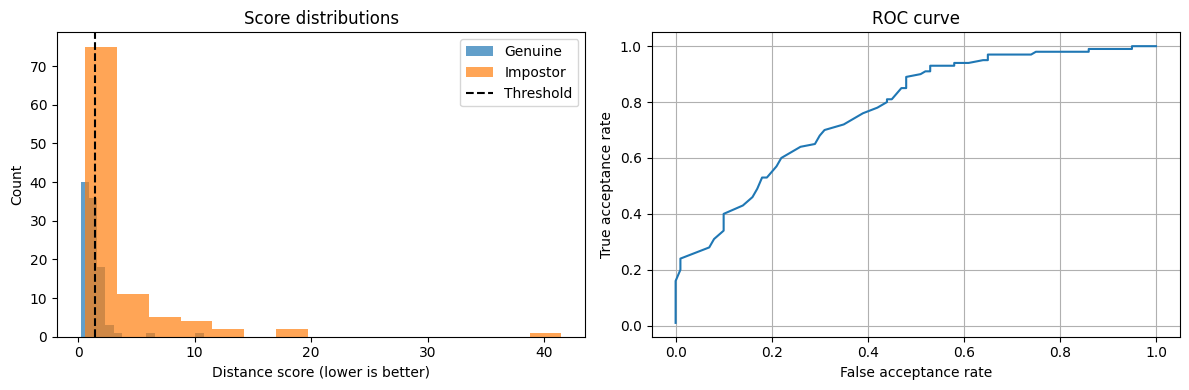

In [6]:
def evaluate_thresholds(results):
    genuine = results.loc[results.label == 'genuine', 'score'].to_numpy()
    impostor = results.loc[results.label == 'impostor', 'score'].to_numpy()
    thresholds = np.linspace(min(results.score), max(results.score), 1001)
    rows = []
    for threshold in thresholds:
        far = np.mean(impostor <= threshold)
        frr = np.mean(genuine > threshold)
        rows.append((threshold, far, frr))
    curve = pd.DataFrame(rows, columns=['threshold', 'far', 'frr'])
    curve['gap'] = np.abs(curve.far - curve.frr)
    eer_row = curve.loc[curve.gap.idxmin()]
    return curve, float(eer_row.threshold), float((eer_row.far + eer_row.frr) / 2)

curve, threshold, eer = evaluate_thresholds(baseline)
print(f'Selected threshold: {threshold:.4f}')
print(f'Estimated EER: {eer:.3%}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(baseline.loc[baseline.label == 'genuine', 'score'], bins=15, alpha=.7, label='Genuine')
axes[0].hist(baseline.loc[baseline.label == 'impostor', 'score'], bins=15, alpha=.7, label='Impostor')
axes[0].axvline(threshold, color='black', linestyle='--', label='Threshold')
axes[0].set(xlabel='Distance score (lower is better)', ylabel='Count', title='Score distributions')
axes[0].legend()
axes[1].plot(curve.far, 1 - curve.frr)
axes[1].set(xlabel='False acceptance rate', ylabel='True acceptance rate', title='ROC curve')
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 5. Sequential adaptive profile

The adaptive profile updates after an accepted **known genuine** sample. This controlled update is useful for measuring adaptation, but it is optimistic because a deployed system would not know the label. A later experiment should compare this with an unlabeled update policy and measure impostor-poisoning risk.

        fixed_score  adaptive_score
sample                             
5          1.898555        1.898555
6          1.593706        1.563176
7          1.077888        1.036088
8          1.293574        1.263914
9          1.251077        1.196092
10         1.248720        1.185942
11         1.239540        1.124873
12         1.047065        0.951861
13         1.250835        1.123775
14         1.368977        1.253381


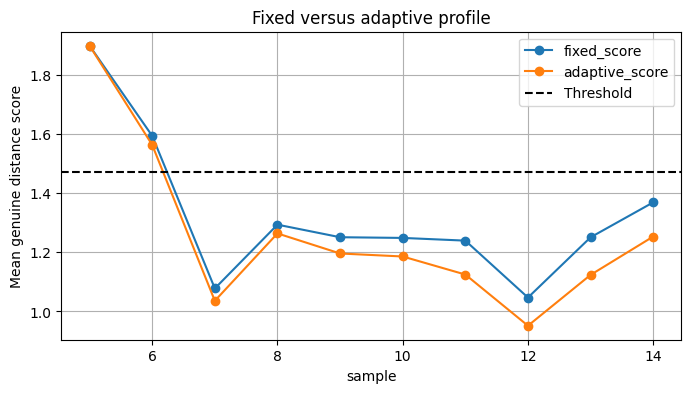

In [7]:
def adaptive_experiment(alpha=0.05):
    rows = []
    for user_id in range(1, N_USERS + 1):
        user_data = data[data.user == user_id].sort_values('sample')
        profile = {'mean': profiles[user_id]['mean'].copy(), 'scale': profiles[user_id]['scale'].copy()}
        for _, row in user_data[user_data['sample'].isin(GENUINE)].iterrows():
            vector = row[feature_names].to_numpy(float)
            score = distance_score(profile, vector)
            accepted = score <= threshold
            rows.append({'user': user_id, 'sample': int(row['sample']), 'score': score,
                         'accepted': accepted, 'label': 'genuine', 'alpha': alpha})
            if accepted:
                old_mean = profile['mean'].copy()
                profile['mean'] = (1 - alpha) * profile['mean'] + alpha * vector
                deviation = np.abs(vector - old_mean)
                profile['scale'] = np.maximum((1 - alpha) * profile['scale'] + alpha * deviation, 1e-6)
    return pd.DataFrame(rows)

adaptive = adaptive_experiment(alpha=0.05)
comparison = baseline[baseline.label == 'genuine'][['user', 'sample', 'score']].rename(columns={'score': 'fixed_score'})
comparison = comparison.merge(adaptive[['user', 'sample', 'score']].rename(columns={'score': 'adaptive_score'}), on=['user', 'sample'])
print(comparison.groupby('sample')[['fixed_score', 'adaptive_score']].mean())

comparison.groupby('sample')[['fixed_score', 'adaptive_score']].mean().plot(marker='o', figsize=(8, 4))
plt.axhline(threshold, color='black', linestyle='--', label='Threshold')
plt.ylabel('Mean genuine distance score')
plt.title('Fixed versus adaptive profile')
plt.grid(True)
plt.legend()
plt.show()

## 6. Optional synthetic timing-drift experiment

This does not create real longitudinal data. It stress-tests the model by scaling timing-related features. A scale greater than 1 represents slower behavior; a scale below 1 represents faster behavior.

,scale,mean_score,acceptance_rate
0,0.8,1.919208,0.34
1,0.9,1.542791,0.57
2,1.0,1.326994,0.70
3,1.1,1.458024,0.71
4,1.2,1.751721,0.66
5,1.3,2.180552,0.50


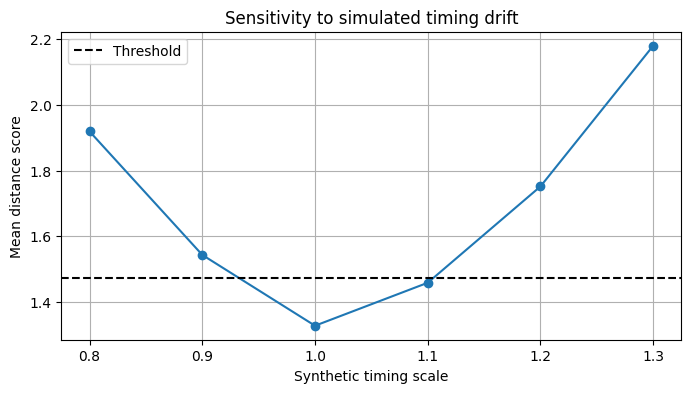

In [8]:
timing_columns = [name for name in feature_names if any(prefix in name for prefix in ['hold_', 'event_', 'press_interval_', 'flight_', 'duration'])]
drift_results = []
for scale in [0.80, 0.90, 1.00, 1.10, 1.20, 1.30]:
    for _, row in data[data['sample'].isin(GENUINE)].iterrows():
        vector = row[feature_names].to_numpy(float).copy()
        for column in timing_columns:
            vector[feature_names.index(column)] *= scale
        score = distance_score(profiles[int(row.user)], vector)
        drift_results.append({'scale': scale, 'user': int(row.user), 'sample': int(row['sample']), 'score': score})
drift_results = pd.DataFrame(drift_results)
drift_summary = drift_results.groupby('scale').agg(mean_score=('score', 'mean'), acceptance_rate=('score', lambda x: np.mean(x <= threshold))).reset_index()
display(drift_summary)

fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(drift_summary.scale, drift_summary.mean_score, marker='o')
axis.axhline(threshold, color='black', linestyle='--', label='Threshold')
axis.set(xlabel='Synthetic timing scale', ylabel='Mean distance score', title='Sensitivity to simulated timing drift')
axis.grid(True)
axis.legend()
plt.show()

## Conclusions to report

Report whether adaptation lowers genuine false-rejection rates without increasing impostor acceptance. Include the threshold, EER, score-distribution plot, fixed/adaptive comparison, and synthetic-drift result.

The defensible conclusion is about **keystroke dynamics**. Do not describe this dataset as multimodal. The next stage would collect synchronized scrolling/touch and gait features, then replace or extend the single feature vector with modality-specific encoders and a fusion layer.